# 03-features — Trích đặc trưng

**Câu hỏi**: phase 2 nhận đặc trưng gì (CLS hay pooler, `fz` hay `ft`), và đặc trưng đó chứa bao nhiêu thông tin để phân biệt các lớp mới? (D8, Q03.02, Q14.04)

   ### Nguồn gốc (provenance)

   In commit và trạng thái dirty của code, rồi đặt `XLA_FLAGS` trước mọi lần import jax (mẫu ở `lab/README.vi.md` §11).

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit 094a048 | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


   - **Kết quả**: commit `094a048`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.

## 1. Đặc trưng

### 1.1 Tám bộ đặc trưng: mã băm, shape, khoảng giá trị

Với mỗi bộ (GC10, NEU × `fz`, `ft` r0–r2):
- tính lại `exp.hash_path` của thư mục đặc trưng;
- đếm số run có `config.json` ghi đúng mã băm đó. Đếm theo mã, không theo đường dẫn, vì bộ `fz` của GC10 đã đổi tên thư mục ngày 5/10 nhưng nội dung trùng từng bit;
- in shape, dtype, min, max, và tỉ lệ giá trị có |x| > 0.99.

`ft` lấy từ pooler (tanh) nên phải nằm trong [−1, 1]; `fz` là CLS nên không bị chặn (D8).

In [2]:
# cell 1: the 8 feature sets: exp.hash_path now, against the hashes that runs recorded in config.json (any path);
#         shape, dtype, value range, share of values with |x| > 0.99
import collections, importlib.util, json
import numpy as np, pandas as pd
spec = importlib.util.spec_from_file_location("exp", "scripts/exp.py")
exp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exp)
recorded = collections.Counter()                                 # hash -> number of runs that read a feature folder with it
for c in Path("runs").glob("*/config.json"):
    for k, v in (json.loads(c.read_text()).get("inputs") or {}).items():
        if k.startswith("features/"):
            recorded[v] += 1
rows = []
for d in sorted(Path("runs").glob("*__*_f[tz]_cls*first_img80pct*")):
    if not d.is_dir() or "_km_" in d.name:
        continue
    sub = "dino-vitb16" if "_fz_" in d.name else "dino-vitb16-sl"
    F = Path("features") / d.name / sub
    X, T = np.load(F / f"features-{sub}.npy"), np.load(F / f"test_features-{sub}.npy")
    h = exp.hash_path(F)
    rows.append(dict(set=d.name.split("__")[1], hash=h, runs_with_hash=recorded[h], train=X.shape, test=T.shape, dtype=str(X.dtype),
                     min=round(float(min(X.min(), T.min())), 3), max=round(float(max(X.max(), T.max())), 3),
                     abs_gt_099=f"{np.mean(np.abs(np.vstack([X, T])) > 0.99):.2%}"))
feat = pd.DataFrame(rows)
print(feat.to_string(index=False))

                          set             hash  runs_with_hash       train       test   dtype     min    max abs_gt_099
   gc10_fz_cls5first_img80pct 703bbd7767fa2e84              15 (1833, 768) (455, 768) float32 -19.001 17.354     60.80%
gc10_ft_cls5first_img80pct_r0 fd74685286cd2076              21 (1833, 768) (455, 768) float32  -1.000  1.000      3.93%
gc10_ft_cls5first_img80pct_r1 9295da71700c68e1              20 (1833, 768) (455, 768) float32  -1.000  1.000      4.36%
gc10_ft_cls5first_img80pct_r2 6e386b3491060007              20 (1833, 768) (455, 768) float32  -1.000  1.000      4.29%
    neu_fz_cls3first_img80pct d493c7c5b0b20b32               0 (1440, 768) (360, 768) float32 -16.286 18.751     61.01%
 neu_ft_cls3first_img80pct_r0 f4e133077ffb8c28               5 (1440, 768) (360, 768) float32  -1.000  1.000      4.07%
 neu_ft_cls3first_img80pct_r1 2d5d07a8ff348404               5 (1440, 768) (360, 768) float32  -1.000  1.000      3.72%
 neu_ft_cls3first_img80pct_r2 4995500008

- **Kết quả**: 8 bộ, float32. GC10: train 1833, test 455; NEU: train 1440, test 360; đều 768 chiều.
  - Mã băm hiện tại trùng mã đã ghi trong `config.json`:
    - GC10 `fz` `703bbd77…`: 15 run (5 run đọc tên thư mục cũ `20260930_232359__gc10_extract_frozen`, 10 run đọc tên mới);
    - GC10 `ft` r0, r1, r2: mỗi bộ 20 run;
    - NEU `ft` r0, r1, r2: mỗi bộ 5 run.
  - NEU `fz` (`d493c7c5…`) chưa run nào đọc.
  - `ft` nằm đúng trong [−1.000, 1.000], 3.7–4.4% giá trị có |x| > 0.99. `fz` trải từ −19.0 đến 18.8.
- **Ý nghĩa**:
  - Mọi bộ đặc trưng mà các run đã dùng vẫn nằm nguyên trên đĩa, trùng từng byte (QD23).
  - Khoảng giá trị xác nhận D8: `ft` đi qua tanh của pooler, `fz` là CLS không bị chặn. Hai bộ khác nhau cả về thang đo, không chỉ ở chuyện có fine-tune hay không.
  - Cột |x| > 0.99 chỉ có nghĩa với `ft`: khoảng 4% số chiều bão hoà ở ±1, chỗ đó tanh làm mất thông tin về độ lớn.

### 1.2 Kiểm đầu cuối cho `ft`

Như 01 §4.1, nhưng với mô hình đã fine-tune. Dựng mô hình bằng `load_model()` (02 §1.2), nạp checkpoint `ft_ckpt.pt` (gồm cả pooler, PATCH 5), chuyển sang eval, trích `pooler_output` cho 128 ảnh train đầu (batch đầu khi trích), rồi so với hàng 0–127 của file `ft`. Làm cho GC10 r0 và NEU r0.

**Quy tắc đạt** (chốt trước khi chạy): cosine nhỏ nhất ≥ 0.9999 ở cả hai bộ. Không đạt thì checkpoint không tái tạo được đặc trưng, và mọi phân tích dựa trên checkpoint (02 §2) phải xem lại.

In [3]:
# cell 2: end-to-end check of ft: rebuild the fine-tuned model from its checkpoint (load_model + PATCH 5 state, pooler
#         included), re-extract the first batch (128 train images) as dino-neudet.py did, compare with rows 0-127 of the file
import os, sys
import torch, torchvision
from PIL import Image
import data_io
os.environ.setdefault("HF_HUB_OFFLINE", "1")
sys.path.insert(0, str(ROOT / "feature_extractor"))
from sl_finetuned_model import load_model
norm = [torchvision.transforms.ToTensor(), torchvision.transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))]
TFM = {"gc10": torchvision.transforms.Compose([torchvision.transforms.Resize((224, 224), 3)] + norm),              # --resize full
       "neudet": torchvision.transforms.Compose([torchvision.transforms.Resize(256, 3), torchvision.transforms.CenterCrop(224)] + norm)}
dev = "cuda" if torch.cuda.is_available() else "cpu"
for ds, tag, k in (("gc10", "gc10_ft_cls5first_img80pct_r0", 10), ("neudet", "neu_ft_cls3first_img80pct_r0", 6)):
    run = next(Path("features").glob(f"*__{tag}"))
    model = load_model(k, "dino_vitb16")                         # num_classes = len(split["classes"]), as dino-neudet.py
    miss, extra = model.load_state_dict(torch.load(run / "ft_ckpt.pt", map_location="cpu", weights_only=True)["state"], strict=False)
    assert not extra and not any(p.requires_grad or "pooler.dense" in n for n, p in model.named_parameters() if n in miss)
    backbone = model.backbone.to(dev).eval()                     # finetune_dino returns lora_model.backbone; extract() sets eval()
    imgs = data_io.images(ds)
    paths = imgs[imgs["part"] == "train"].sort_values("row")["path"].iloc[:128]
    x = torch.stack([TFM[ds](Image.open(p).convert("RGB")) for p in paths]).to(dev)
    with torch.no_grad():
        f = backbone(x).pooler_output.cpu().numpy()              # extract(..., cls=False): pooler_output
    ref = np.load(run / "dino-vitb16-sl" / "features-dino-vitb16-sl.npy")[:128]
    cos = (f * ref).sum(1) / np.linalg.norm(f, axis=1) / np.linalg.norm(ref, axis=1)
    print(f"{ds}: {run.name} | rows 0-127 | bit-identical {np.array_equal(f, ref)} | max|diff| {np.abs(f - ref).max():.2e} "
          f"| min cosine {cos.min():.7f}")

/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Using /home/rito/.cache/torch_extensions/py312_cu121 as PyTorch extensions root...
Detected CUDA files, patching ldflags
Emitting ninja build file /home/rito/.cache/torch_extensions/py312_cu121/fbd_cuda/build.ninja...
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/torch/utils/cpp_extension.py:1965: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all archs for visible cards are included for compilation. 
If this is not desired, please s

[1/1] gcc fbd_cuda.o fbd_cuda_kernel.cuda.o -shared -L/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/torch/lib -lc10 -lc10_cuda -ltorch_cpu -ltorch_cuda -ltorch -ltorch_python -L/home/rito/miniforge3/envs/vbcgcd/lib -lcudart -o fbd_cuda.so
FAILED: [code=1] fbd_cuda.so 
gcc fbd_cuda.o fbd_cuda_kernel.cuda.o -shared -L/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/torch/lib -lc10 -lc10_cuda -ltorch_cpu -ltorch_cuda -ltorch -ltorch_python -L/home/rito/miniforge3/envs/vbcgcd/lib -lcudart -o fbd_cuda.so
/usr/bin/ld: cannot find -lcudart: No such file or directory
collect2: error: ld returned 1 exit status
ninja: build stopped: subcommand failed.


/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:95: UserWarning: Failed to load the CUDA extension: Error building extension 'fbd_cuda', check if ninja is available.
  warnings.warn(f"Failed to load the CUDA extension: {e}, check if ninja is available.")
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:96: UserWarning: Setting boft_n_butterfly_factor to 1 to speed up the finetuning process.
  warnings.warn("Setting boft_n_butterfly_factor to 1 to speed up the finetuning process.")
Using /home/rito/.cache/torch_extensions/py312_cu121 as PyTorch extensions root...
No modifications detected for re-loaded extension module fbd_cuda, skipping build step...
Loading extension module fbd_cuda...
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:95: UserWarning: Failed to load the CUDA extension: /home/rito/.cache/torch_extensions/py312_cu121/fbd_cuda/fbd_cuda.so: cannot open s

trainable params: 221,184 || all params: 86,592,000 || trainable%: 0.2554


Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


gc10: 20261005_013115__gc10_ft_cls5first_img80pct_r0 | rows 0-127 | bit-identical True | max|diff| 0.00e+00 | min cosine 0.9999999


Using /home/rito/.cache/torch_extensions/py312_cu121 as PyTorch extensions root...
No modifications detected for re-loaded extension module fbd_cuda, skipping build step...
Loading extension module fbd_cuda...
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:95: UserWarning: Failed to load the CUDA extension: /home/rito/.cache/torch_extensions/py312_cu121/fbd_cuda/fbd_cuda.so: cannot open shared object file: No such file or directory, check if ninja is available.
  warnings.warn(f"Failed to load the CUDA extension: {e}, check if ninja is available.")
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:96: UserWarning: Setting boft_n_butterfly_factor to 1 to speed up the finetuning process.
  warnings.warn("Setting boft_n_butterfly_factor to 1 to speed up the finetuning process.")
Using /home/rito/.cache/torch_extensions/py312_cu121 as PyTorch extensions root...
No modifications detected for re-loaded extension

trainable params: 221,184 || all params: 86,592,000 || trainable%: 0.2554
neudet: 20261005_014947__neu_ft_cls3first_img80pct_r0 | rows 0-127 | bit-identical True | max|diff| 0.00e+00 | min cosine 0.9999999


- **Kết quả**: GC10 `ft` r0 và NEU `ft` r0: 128 hàng trích lại trùng từng bit với file (max|diff| = 0, cosine nhỏ nhất 0.9999999). Mô hình dựng lại đều có 221,184 tham số học được (factor 1).
- **Ý nghĩa**: đạt quy tắc, ở mức trùng từng bit.
  - Checkpoint `ft_ckpt.pt` gồm BOFT, head và pooler (PATCH 5), cộng với trọng số DINO gốc, tái tạo đúng mô hình đã sinh ra đặc trưng `ft`. Các phân tích dựa trên checkpoint ở 02 §2 là phân tích trên chính mô hình đó.
  - Cùng với 01 §4.1, cả chuỗi bước 01–03 đã được kiểm từ ảnh gốc tới file đặc trưng, cho cả `fz` lẫn `ft`.
  - Pooler lấy từ checkpoint, không phải khởi tạo lại. [SUY LUẬN] Nếu khởi tạo lại, pooler sẽ phụ thuộc trạng thái RNG lúc dựng mô hình; PATCH 5 gỡ được sự phụ thuộc này.

### 1.3 CLS hay pooler (D8)

Đặc trưng `ft` không phải token CLS mà là `pooler_output` = tanh(W · CLS + b). W (768 × 768) và b là pooler của Hugging Face, không thuộc DINO, được khởi tạo ngẫu nhiên và không học (02 §1.2).

**Cách làm**: dựng lại mô hình GC10 `ft` r0, cho 455 ảnh test chạy qua theo batch 128 như lúc trích, lấy cả CLS lẫn pooler. Kiểm:
1. tính tay tanh(W · CLS + b) có trùng `pooler_output` không, và pooler có trùng file `test_features` không;
2. phân bố của giá trị trước tanh (z = W · CLS + b): tỉ lệ |z| > 2.65, tức |tanh| > 0.99 (vùng bão hoà);
3. pooler có giữ khoảng cách giữa các ảnh không: tương quan hạng Spearman giữa khoảng cách đôi một (Euclid và cosine) tính trên CLS và tính trên pooler, qua 455 · 454 / 2 = 103,285 cặp.

Tương quan gần 1 nghĩa là pooler gần như chỉ đổi thang đo; thấp hơn rõ nghĩa là pooler làm méo hình học mà bước 09 (k-means) nhìn thấy.

In [4]:
# cell 3: CLS or pooler (D8), GC10 ft r0 on the 455 test images: pooler_output = tanh(W CLS + b) with the frozen random
#         pooler; how often it saturates, and how well it keeps the distances between images
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
run = next(Path("features").glob("*__gc10_ft_cls5first_img80pct_r0"))
model = load_model(10, "dino_vitb16")
model.load_state_dict(torch.load(run / "ft_ckpt.pt", map_location="cpu", weights_only=True)["state"], strict=False)
bb = model.backbone.to(dev).eval()
imgs = data_io.images("gc10")
paths = imgs[imgs["part"] == "test"].sort_values("row")["path"]
cls, pool = [], []
with torch.no_grad():
    for i in range(0, len(paths), 128):                           # batches of 128 from row 0, as extract()
        o = bb(torch.stack([TFM["gc10"](Image.open(p).convert("RGB")) for p in paths.iloc[i:i + 128]]).to(dev))
        cls.append(o.last_hidden_state[:, 0].cpu().numpy())
        pool.append(o.pooler_output.cpu().numpy())
cls, pool = np.concatenate(cls), np.concatenate(pool)
dense = bb.base_model.model.pooler.dense
W, b = dense.weight.detach().cpu().numpy(), dense.bias.detach().cpu().numpy()
z = cls @ W.T + b                                                # pre-activation
ref = np.load(run / "dino-vitb16-sl" / "test_features-dino-vitb16-sl.npy")
print(f"pooler = tanh(W CLS + b): max|diff| {np.abs(np.tanh(z) - pool).max():.1e} | pooler = stored test features: {np.array_equal(pool, ref)}")
print(f"W: std {W.std():.4f}, |b| max {np.abs(b).max():.4f} | CLS norm median {np.median(np.linalg.norm(cls, axis=1)):.2f}")
print(f"pre-activation z: std {z.std():.3f}, share |z| > 2.65 (|tanh| > 0.99): {np.mean(np.abs(z) > 2.65):.2%}, "
      f"share |z| < 0.5 (near linear): {np.mean(np.abs(z) < 0.5):.2%}")
for metric in ("euclidean", "cosine"):
    rho = spearmanr(pdist(cls, metric), pdist(pool, metric))[0]
    print(f"pairwise {metric} distances, CLS vs pooler: Spearman {rho:.4f} over {len(pdist(cls[:, :1])):,} pairs")

Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Using /home/rito/.cache/torch_extensions/py312_cu121 as PyTorch extensions root...
No modifications detected for re-loaded extension module fbd_cuda, skipping build step...
Loading extension module fbd_cuda...
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:95: UserWarning: Failed to load the CUDA extension: /home/rito/.cache/torch_extensions/py312_cu121/fbd_cuda/fbd_cuda.so: cannot open shared object file: No such file or directory, check if ninja is available.
  warnings.warn(f"Failed to load the CUDA extension: {e}, check if ninja is available.")
/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/peft/tuners/boft/layer.py:96: UserWarning: Setting boft_n_but

trainable params: 221,184 || all params: 86,592,000 || trainable%: 0.2554
pooler = tanh(W CLS + b): max|diff| 2.9e-06 | pooler = stored test features: True
W: std 0.0200, |b| max 0.0000 | CLS norm median 64.18
pre-activation z: std 1.278, share |z| > 2.65 (|tanh| > 0.99): 3.88%, share |z| < 0.5 (near linear): 30.50%
pairwise euclidean distances, CLS vs pooler: Spearman 0.9835 over 103,285 pairs
pairwise cosine distances, CLS vs pooler: Spearman 0.9829 over 103,285 pairs


- **Kết quả**:
  - Tính tay tanh(W · CLS + b) trùng `pooler_output` tới 2.9e-06; pooler của 455 ảnh test trùng từng bit với file `test_features`.
  - W có độ lệch chuẩn 0.0200, b = 0.
  - Chuẩn của CLS (trung vị) là 64.18.
  - Giá trị trước tanh có độ lệch chuẩn 1.278. 3.88% số giá trị nằm ở vùng bão hoà (|z| > 2.65); 30.50% nằm ở vùng gần tuyến tính (|z| < 0.5).
  - Tương quan Spearman giữa khoảng cách trên CLS và trên pooler, qua 103,285 cặp: 0.9835 (Euclid), 0.9829 (cosine).
- **Ý nghĩa**:
  - Pooler là một phép chiếu ngẫu nhiên Gauss (khởi tạo mặc định của Hugging Face: chuẩn với std 0.02, bias 0), theo sau là tanh.
  - Độ lệch chuẩn của z khớp phép tính tay: 0.02 × 64.18 ≈ 1.28. Mỗi z_i là tổng có trọng số ngẫu nhiên của CLS, nên có độ lệch chuẩn ≈ std(W) · ‖CLS‖.
  - Phép chiếu ngẫu nhiên gần như giữ khoảng cách (bổ đề Johnson–Lindenstrauss), và tanh chỉ nén khoảng 4% giá trị. Vì vậy thứ tự khoảng cách gần như giữ nguyên (Spearman 0.98).
  - [SUY LUẬN] D8 (dùng pooler thay CLS) chỉ làm méo nhẹ hình học mà k-means ở bước 09 nhìn thấy. Nó khó là nguyên nhân chính của khác biệt giữa `fz` và `ft`; phần khác biệt chủ yếu đến từ fine-tune. Đây mới là thứ hạng khoảng cách, chưa phải cấu trúc cụm, nên không loại hẳn được ảnh hưởng tới phân cụm.

## 2. `fz` và `ft`

### 2.1 Fine-tune dịch ảnh bao xa, và ba FT seed có cùng hình học không

**Cách làm**, trên 455 ảnh test GC10:
1. Với mỗi ảnh, tính cosine giữa CLS của `fz` (file đặc trưng) và CLS của `ft` r0 (tính ở 1.3), cùng một không gian 768 chiều của ViT. In trung vị theo từng lớp, để xem lớp cũ (dữ liệu fine-tune) hay lớp mới bị dịch nhiều hơn.
2. Với bốn bộ đặc trưng đã lưu (`fz`, `ft` r0, r1, r2), tính ma trận tương quan Spearman giữa các khoảng cách cosine đôi một.

Tương quan giữa các seed `ft` cao: ba seed cho cùng hình học dù tham số học khác hướng (02 §2.3). Thấp: mỗi seed là một bộ đặc trưng khác hẳn.

In [5]:
# cell 4: how far fine-tuning moves each test image (cosine of fz CLS and ft r0 CLS, by class), and whether fz and the
#         3 ft seeds give the same geometry (Spearman correlation of pairwise cosine distances, 455 GC10 test images)
split = json.loads(Path(data_io.SPLITS["gc10"]).read_text())
TEST = {}
for name, tag, sub in (("fz", "gc10_fz_cls5first_img80pct", "dino-vitb16"),) + tuple(
        (f"ft r{r}", f"gc10_ft_cls5first_img80pct_r{r}", "dino-vitb16-sl") for r in range(3)):
    F = next(Path("features").glob(f"*__{tag}")) / sub
    TEST[name] = np.load(F / f"test_features-{sub}.npy")
    if name == "fz":
        y = np.load(F / f"test_labels-{sub}.npy").astype(int)
cos_move = (TEST["fz"] * cls).sum(1) / np.linalg.norm(TEST["fz"], axis=1) / np.linalg.norm(cls, axis=1)
print(pd.DataFrame(dict(cls=[split["classes"][k] for k in y], cos=cos_move)).groupby("cls", sort=False)["cos"]
      .agg(["count", "median", "min"]).round(3).to_string())
D = {k: pdist(v, "cosine") for k, v in TEST.items()}
print("\nSpearman of pairwise cosine distances:")
print(pd.DataFrame({a: {b: spearmanr(D[a], D[b])[0] for b in D} for a in D}).round(3).to_string())

               count  median    min
cls                                
punching_hole     43   0.775  0.638
welding_line      54   0.773  0.665
crescent_gap      45   0.786  0.651
water_spot        58   0.756  0.589
oil_spot          41   0.760  0.636
silk_spot        124   0.745  0.600
inclusion         43   0.741  0.646
rolled_pit         6   0.763  0.724
crease            11   0.780  0.655
waist_folding     30   0.833  0.719

Spearman of pairwise cosine distances:
          fz  ft r0  ft r1  ft r2
fz     1.000  0.751  0.779  0.784
ft r0  0.751  1.000  0.926  0.927
ft r1  0.779  0.926  1.000  0.932
ft r2  0.784  0.927  0.932  1.000


- **Kết quả**:
  - Cosine giữa CLS `fz` và CLS `ft` r0 của cùng một ảnh, trung vị theo lớp: 0.741 (inclusion) đến 0.833 (waist_folding); thấp nhất 0.589 (một ảnh water_spot). Lớp cũ 0.756–0.786, lớp mới 0.741–0.833.
  - Tương quan Spearman giữa khoảng cách cosine: `fz` với các seed `ft` là 0.751–0.784; giữa các seed `ft` là 0.926–0.932.
- **Ý nghĩa**:
  - Fine-tune dịch mọi ảnh khá xa (cosine khoảng 0.75, tức góc khoảng 40°) và dịch đều nhau. Lớp cũ, dù là dữ liệu fine-tune, không bị dịch nhiều hơn lớp mới.
  - Ba seed `ft` cho hình học rất giống nhau (0.93), dù tham số học được ở lớp sâu gần như không tương quan (02 §2.3). [SUY LUẬN] Có nhiều cách xoay khác nhau dẫn tới gần cùng một biểu diễn.
  - Hình học chung gần nhau, nhưng khám phá lớp mới vẫn dao động theo FT seed (balanced novel 39.4 / 29.2 / 36.2, E09.05). [SUY LUẬN] Phần khác biệt (khoảng 7%) có thể nằm đúng ở vùng của các lớp hiếm, mà tương quan toàn cục không thấy. Probe theo lớp ở mục 3 đo được điều này.

## 3. Probe theo lớp (E03.02)

### 3.1 Số chính thức của E03.02

Probe tuyến tính (linear probe) học có nhãn trên đặc trưng, để đo xem thông tin về lớp có trong đặc trưng tới đâu. So với recall của pipeline, nó cho biết điểm mất nằm ở biểu diễn hay ở khám phá. Tiền đăng ký ở `notes/pl/experiments.vi.md` E03.02 (commit `afdeb1d`); code `tier1_03` trong `lab/score.py` (`b89f1d6`); run `gc10_e03_02`.

**Cách làm**: đọc `config.json` và `metrics.json` của run, rồi in:
- commit lúc chạy, trạng thái dirty, `checks_ok`;
- bảng cho mỗi lớp mới và mỗi bộ: probe quyết định `lr_bal` (k/n), recall của pipeline, và nhãn D, R, U theo quy tắc;
- balanced novel của 4 probe và của pipeline.

In [6]:
# cell 5: E03.02, official numbers: metrics.json of run gc10_e03_02 (lab/score.py tier1_03; pre-registration afdeb1d)
run = next(Path("runs").glob("*__gc10_e03_02"))
cfg, m = (json.loads((run / f).read_text()) for f in ("config.json", "metrics.json"))
print("run", run.name, "| commit", cfg["git"]["commit"][:7], "| dirty", cfg["git"]["dirty"], "| checks_ok", m["checks_ok"])
SETS, NOV = ["fz", "r0", "r1", "r2"], ["silk_spot", "inclusion", "rolled_pit", "crease", "waist_folding"]
print("\nlr_bal probe k/n | pipeline recall (5 seeds) | type (D lost at discovery, R weak representation, U undetermined)")
print(pd.DataFrame({s: {c: f'{m[f"lr_bal_{s}_{c}_k"]}/{m[f"lr_bal_{s}_{c}_n"]} | {m[f"pipe_{s}_{c}_recall"]:.3f} | '
                           f'{m[f"type_{s}_{c}"]}' for c in NOV} for s in SETS}).to_string())
print("\nbalanced novel accuracy on the test set:")
print(pd.DataFrame({p: {s: m[f"{p}_{s}_bal_novel"] for s in SETS} for p in ("lr", "lr_bal", "knn", "pca_lr_bal", "pipe")}).to_string())

run 20261101_165324__gc10_e03_02 | commit 32cf2a4 | dirty False | checks_ok 1

lr_bal probe k/n | pipeline recall (5 seeds) | type (D lost at discovery, R weak representation, U undetermined)
                                fz                  r0                  r1                   r2
silk_spot      111/124 | 0.664 | D  84/124 | 0.682 | U  96/124 | 0.421 | D  105/124 | 0.639 | D
inclusion        22/43 | 0.140 | D   24/43 | 0.163 | D   27/43 | 0.074 | D    25/43 | 0.181 | D
rolled_pit         4/6 | 0.000 | U     3/6 | 0.000 | U     3/6 | 0.000 | U      3/6 | 0.000 | U
crease            5/11 | 0.109 | R    5/11 | 0.345 | R    6/11 | 0.000 | D     8/11 | 0.054 | D
waist_folding    25/30 | 0.967 | U   26/30 | 0.780 | U   28/30 | 0.967 | U    27/30 | 0.933 | U

balanced novel accuracy on the test set:
        lr  lr_bal     knn  pca_lr_bal    pipe
fz  0.6662  0.6723  0.4448      0.5621  0.3760
r0  0.6226  0.6114  0.5088      0.6405  0.3941
r1  0.6568  0.6762  0.4837      0.5696  0.2924
r2

- **Kết quả**: run `20261101_165324__gc10_e03_02`, chạy ở commit `32cf2a4`, không dirty, `checks_ok` 1.
  - Probe `lr_bal` so với recall của pipeline (cộng 5 seed):
    - crease: 5/11 | 0.109 (`fz`), 5/11 | 0.345 (r0), 6/11 | 0.000 (r1), 8/11 | 0.054 (r2); nhãn R, R, D, D;
    - rolled_pit: 4/6 hoặc 3/6, pipeline 0.000, U ở cả 4 bộ;
    - inclusion: 22–27/43 so với 0.074–0.181, D ở cả 4 bộ.
  - Balanced novel:
    - `lr_bal`: 0.672 / 0.611 / 0.676 / 0.711 (`fz` / r0 / r1 / r2);
    - `pca_lr_bal`: 0.562 / 0.641 / 0.570 / 0.612;
    - `knn`: 0.445–0.509;
    - pipeline: 0.376 / 0.394 / 0.292 / 0.362.
- **Ý nghĩa**: theo quy tắc đã tiền đăng ký, crease mang D (r1, r2) và rolled_pit là U, nên E09.06 vẫn là thí nghiệm kế tiếp (`experiments.vi.md` E03.02).
  - Với cùng đặc trưng, bộ phân lớp tuyến tính có nhãn đọc được gần gấp đôi pipeline (0.61–0.71 so với 0.29–0.39). Phần lớn chỗ mất nằm sau bước 03.
  - [SUY LUẬN] Ba con số đáng nhớ cho các bước sau:
    - r1 có probe tốt (0.676) nhưng pipeline kém nhất (0.292). Độ bất ổn theo FT seed nằm ở khâu khám phá chứ không ở đặc trưng, nối với 2.1;
    - PCA-64 không mất gì ở r0 nhưng mất 11 điểm ở r1 và r2. Cần xem lại ở notebook 05;
    - k-NN kém hơn probe tuyến tính khoảng 20 điểm, rõ nhất ở crease (0/11). Lớp hiếm không có láng giềng cùng lớp.

### 3.2 Hình: probe và pipeline theo lớp, kèm khoảng tin cậy

Vẽ recall của probe `lr_bal` và của pipeline cho 5 lớp mới, mỗi bộ đặc trưng một ô, kèm khoảng tin cậy 95% Wilson. Hai khoảng không chồng nhau, với probe ở trên, là nhãn D. Hình giúp thấy ngay vì sao rolled_pit là U: với 6 ảnh, cả hai khoảng đều rất rộng.

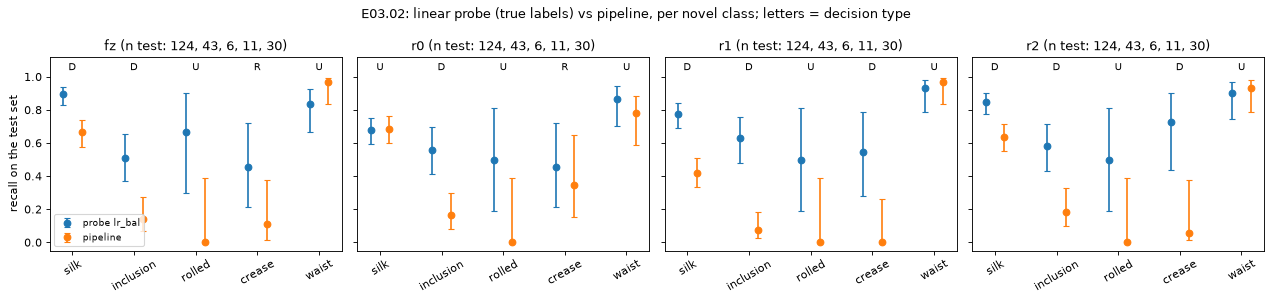

In [7]:
# cell 6: per-class recall of the lr_bal probe and of the pipeline, with 95% Wilson intervals, one panel per feature set
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), dpi=80, sharey=True)
x = np.arange(len(NOV))
for ax, s in zip(axes, SETS):
    for dx, who, color in ((-0.15, "probe lr_bal", "tab:blue"), (0.15, "pipeline", "tab:orange")):
        if who == "pipeline":
            r = np.array([m[f"pipe_{s}_{c}_recall"] for c in NOV])
            lo, hi = (np.array([m[f"pipe_{s}_{c}_{e}"] for c in NOV]) for e in ("lo", "hi"))
        else:
            r = np.array([m[f"lr_bal_{s}_{c}_k"] / m[f"lr_bal_{s}_{c}_n"] for c in NOV])
            lo, hi = (np.array([m[f"lr_bal_{s}_{c}_{e}"] for c in NOV]) for e in ("lo", "hi"))
        ax.errorbar(x + dx, r, yerr=[r - lo, hi - r], fmt="o", capsize=3, color=color, label=who)
    for i, c in enumerate(NOV):
        ax.annotate(m[f"type_{s}_{c}"], (i, 1.04), ha="center", fontsize=9)
    ax.set(title=f"{s} (n test: 124, 43, 6, 11, 30)", xticks=x, ylim=(-0.05, 1.12))
    ax.set_xticklabels([c.split("_")[0] for c in NOV], rotation=30)
axes[0].set_ylabel("recall on the test set")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("E03.02: linear probe (true labels) vs pipeline, per novel class; letters = decision type")
plt.tight_layout()
plt.show()

- **Kết quả**:
  - Trên cả 4 bộ, khoảng tin cậy của probe nằm hẳn trên của pipeline ở inclusion. Ở silk_spot cũng vậy, trừ r0, nơi hai khoảng trùng nhau (0.68 so với 0.68).
  - rolled_pit: khoảng của probe trải từ khoảng 0.19 (0.30 ở `fz`) đến khoảng 0.81–0.90; khoảng của pipeline từ 0 đến 0.39. Hai khoảng chồng nhau ở cả 4 ô.
  - crease: chồng nhau ở `fz` và r0 (pipeline r0 đạt 0.35); tách hẳn ở r1 và r2.
  - waist_folding: probe và pipeline ngang nhau (0.78–0.97).
- **Ý nghĩa**:
  - Hình cho thấy quy tắc D/R/U đọc ra điều gì. Mất ở khám phá rõ nhất ở inclusion và silk_spot (lớp đông). Ở crease thì tuỳ FT seed. rolled_pit không kết luận được, vì với 6 ảnh, khoảng tin cậy rộng gần hết trục.
  - waist_folding là lớp duy nhất pipeline làm tốt ngang probe.
  - [SUY LUẬN] Muốn kết luận về rolled_pit phải có thêm dữ liệu, ví dụ đánh giá chéo trên ảnh train hoặc gộp seed theo cách khác. Riêng tập test hiện tại không đủ.

## Summary (EN)

1. **Features are intact and reproducible.** All 8 feature sets match the hashes recorded in `config.json` (15–20 runs per GC10 set, 5 per NEU `ft` set; NEU `fz` has no phase-2 run yet). Re-extracting the first batch from the fine-tuning checkpoint reproduces `ft` r0 bit for bit for GC10 and NEU (§1.1–1.2). Together with `01-preprocess` §4.1, steps 01–03 are checked from raw image to feature file.
2. **The pooler (D8) is a random projection plus tanh, and nearly keeps the geometry.** `ft` = tanh(W · CLS + b) with W ~ N(0, 0.02²), b = 0. The pre-activation std is 1.278 (≈ 0.02 × CLS norm 64.18), with 3.88% of values saturated. Pairwise distances keep their order (Spearman 0.98) (§1.3).
3. **Fine-tuning moves every image, and seeds agree on the geometry.** The cosine between fz and ft r0 CLS of the same test image is 0.74–0.83 (class medians), similar for old and new classes. Pairwise-distance Spearman is 0.75–0.78 between fz and ft, and 0.93 between ft seeds (§2.1).
4. **E03.02: most novel-class accuracy is lost after step 03.** A class-weighted linear probe with true labels reaches balanced novel 0.61 / 0.68 / 0.71 on ft r0 / r1 / r2; the pipeline reaches 0.39 / 0.29 / 0.36 (fz: 0.67 vs 0.38). By the pre-registered rule, crease is lost at discovery in 2 of 3 ft sets, inclusion in all, and rolled_pit is undetermined (6 test images). E09.06 stays the next experiment (§3.1–3.2; run `gc10_e03_02`).
5. **[inference] Leads for later steps.** PCA-64 costs 0–11 points of probe accuracy (step 05). A 20-NN probe cannot read crease (0/11) where the linear probe can, so neighbour-based clustering needs a rare-class check (Q09.06). FT-seed instability sits in discovery, not in the features: r1 has a good probe (0.68) and the weakest pipeline (0.29).